# Step 3 — Teach the base model to answer questions (fine-tuning), evaluate, export

**What this notebook does, in plain words:** the base model from Step 2 can only *continue* text. Here we show it ~250,000 example conversations (*question → answer*) so it learns the pattern "when a user asks something, reply with an answer, then stop". This is called **supervised fine-tuning (SFT)** — it's the same step that turns a base GPT into a chat assistant, just much smaller.

Then we measure what changed, and export a zip you can run on your own PC with `chat_app.py`.

| Section | What happens |
|---|---|
| 1 | Turn conversations into tokens, with a **loss mask**: the model is only graded on the answers |
| 2 | "Before" snapshot: the base model on fixed questions + HellaSwag |
| 3 | Fine-tuning (~1–1.5 h on one T4) |
| 4 | "After": the same questions, SQuAD exact-match / F1, HellaSwag |
| 5 | Export `tv2_chat_export.zip` → run it on your GTX 1650 |

### How to run
*Add Input* → the Step 1 data **and** the Step 2 notebook output (it contains `pretrained.pt`). *Accelerator → GPU T4 x2* (one GPU is used) or P100. *Internet → On* (for HellaSwag). Then *Save Version → Save & Run All*.

## 0. Setup and pre-flight checks

In [1]:
import os, sys, glob, json, math, time, random, shutil, re, string, collections, importlib
import numpy as np
import torch
print(torch.__version__, torch.__file__)
print("dtype:", hasattr(torch, "dtype"), "| _utils:", hasattr(torch, "_utils"))
import torch.nn.functional as F
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

def first_existing(paths):
    return next((p for p in paths if p and os.path.exists(p)), None)

manifest_path = first_existing([os.path.join(os.environ.get("LLM_DATA", ""), "manifest.json")]
                               + glob.glob("/kaggle/input/**/manifest.json", recursive=True)
                               + ["./llm_data/manifest.json"])
pretrained_path = first_existing([os.environ.get("PRETRAINED", "")]
                                 + glob.glob("/kaggle/input/**/pretrained.pt", recursive=True)
                                 + ["./tv2_run/pretrained.pt"])
OUT_DIR = "/kaggle/working/tv2_sft" if os.path.isdir("/kaggle/working") else os.path.abspath("./tv2_sft")
os.makedirs(OUT_DIR, exist_ok=True)

problems = []
if not manifest_path: problems.append("Step 1 data not found (manifest.json) — Add Input")
if not pretrained_path: problems.append("pretrained.pt not found — Add Input → Step 2 notebook output (training must have finished)")
if not torch.cuda.is_available() and not SMOKE_TEST: problems.append("no GPU — Settings → Accelerator → GPU")
if not problems:
    DATA_DIR = os.path.dirname(manifest_path)
    manifest = json.load(open(manifest_path))
    pre = torch.load(pretrained_path, map_location="cpu", weights_only=False)
    if pre["config"]["vocab_size"] != manifest["vocab_size"]:
        problems.append("vocab size of pretrained.pt and the data don't match")
    SFT_FILES = {"train": os.path.join(DATA_DIR, "sft", "train.jsonl"), "val": os.path.join(DATA_DIR, "sft", "val.jsonl")}
    for f in SFT_FILES.values():
        if not os.path.exists(f): problems.append(f"missing {f}")
if problems:
    raise RuntimeError("Pre-flight failed:\n- " + "\n- ".join(problems))

dev = "cuda" if torch.cuda.is_available() else "cpu"
amp_dtype = (torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16) if dev == "cuda" else None
autocast = (lambda: torch.autocast("cuda", dtype=amp_dtype)) if amp_dtype else (lambda: torch.autocast("cpu", enabled=False))
print(f"data: {DATA_DIR}\nbase model: {pretrained_path} ({pre.get('tokens', 0)/1e9:.2f}B tokens of pretraining)")
print(f"device: {torch.cuda.get_device_name() if dev == 'cuda' else 'cpu'} | amp: {amp_dtype} | output: {OUT_DIR}")

2.11.0+cu130 /usr/local/lib/python3.13/dist-packages/torch/__init__.py
dtype: True | _utils: True
data: /kaggle/input/notebooks/prashant554/data-prep/llm_data
base model: /kaggle/input/notebooks/prashant554/transformer-v2/tv2_run/pretrained.pt (1.50B tokens of pretraining)
device: Tesla T4 | amp: torch.float16 | output: /kaggle/working/tv2_sft


In [2]:
%%writefile model_v2.py
"""model_v2.py — a ~100M GPT with modern (Llama-style) parts.

Shared by the pretraining notebook, the fine-tuning notebook and chat_app.py.
For Mamba / Jamba later, only this file changes; train.py and the notebooks stay the same.

Parts (each explained in the notebook):
  RMSNorm        normalise by root-mean-square (no mean subtraction, no bias)
  RoPE           rotary position embeddings
  GQA attention  12 query heads share 4 key/value heads -> 3x smaller KV-cache
  QK-norm        RMSNorm on queries and keys -> attention scores can't blow up in fp16
  SwiGLU MLP     gated feed-forward: down( silu(gate(x)) * up(x) )
"""
import math
from dataclasses import dataclass, asdict

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class ModelConfig:
    vocab_size: int = 32768
    n_layer: int = 12
    n_head: int = 12
    n_kv_head: int = 4
    d_model: int = 768
    ffn_hidden: int = 2048
    block_size: int = 1024          # training context length
    max_pos: int = 4096             # RoPE table length (lets benchmarks go past block_size)
    rope_base: float = 10000.0
    qk_norm: bool = True
    dropout: float = 0.0
    norm_eps: float = 1e-5

    @property
    def head_dim(self):
        return self.d_model // self.n_head

    def validate(self):
        assert self.d_model % self.n_head == 0, "d_model must be divisible by n_head"
        assert self.n_head % self.n_kv_head == 0, "n_head must be divisible by n_kv_head"
        assert self.head_dim % 2 == 0, "RoPE needs an even head_dim"
        assert self.max_pos >= self.block_size
        return self

    def to_dict(self):
        return asdict(self)


class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return xf.type_as(x) * self.weight


def build_rope_cache(max_pos, head_dim, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))
    angles = torch.outer(torch.arange(max_pos).float(), inv_freq)        # (max_pos, hd/2)
    return angles.cos(), angles.sin()


def apply_rope(x, cos, sin):
    # x: (B, H, T, hd); cos/sin: (T, hd/2) — rotate each (even, odd) pair of dims
    x1, x2 = x[..., 0::2].float(), x[..., 1::2].float()
    out = torch.stack((x1 * cos - x2 * sin, x1 * sin + x2 * cos), dim=-1).flatten(-2)
    return out.type_as(x)


class Attention(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.n_head, self.n_kv, self.hd = cfg.n_head, cfg.n_kv_head, cfg.head_dim
        self.q = nn.Linear(cfg.d_model, cfg.n_head * self.hd, bias=False)
        self.kv = nn.Linear(cfg.d_model, 2 * cfg.n_kv_head * self.hd, bias=False)
        self.o = nn.Linear(cfg.n_head * self.hd, cfg.d_model, bias=False)
        self.o.SCALE_INIT = True
        self.q_norm = RMSNorm(self.hd, cfg.norm_eps) if cfg.qk_norm else nn.Identity()
        self.k_norm = RMSNorm(self.hd, cfg.norm_eps) if cfg.qk_norm else nn.Identity()
        self.dropout = cfg.dropout

    def forward(self, x, rope, kv_cache=None):
        B, T, _ = x.shape
        q = self.q(x).view(B, T, self.n_head, self.hd).transpose(1, 2)              # (B, H, T, hd)
        kv = self.kv(x).view(B, T, 2, self.n_kv, self.hd)
        k, v = kv[:, :, 0].transpose(1, 2), kv[:, :, 1].transpose(1, 2)             # (B, KV, T, hd)
        q, k = self.q_norm(q), self.k_norm(k)

        past = 0 if (kv_cache is None or kv_cache["k"] is None) else kv_cache["k"].size(2)
        assert past == 0 or T == 1, "with a KV-cache: feed the prompt once, then one token at a time"
        cos, sin = rope
        q = apply_rope(q, cos[past:past + T], sin[past:past + T])
        k = apply_rope(k, cos[past:past + T], sin[past:past + T])
        if kv_cache is not None:                       # the cache stores only the 4 KV heads
            if past:
                k = torch.cat([kv_cache["k"], k], dim=2)
                v = torch.cat([kv_cache["v"], v], dim=2)
            kv_cache["k"], kv_cache["v"] = k, v

        rep = self.n_head // self.n_kv                 # each KV head serves `rep` query heads
        if rep > 1:
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=(past == 0 and T > 1),
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.o(y.transpose(1, 2).contiguous().view(B, T, -1))


class SwiGLU(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.gate = nn.Linear(cfg.d_model, cfg.ffn_hidden, bias=False)
        self.up = nn.Linear(cfg.d_model, cfg.ffn_hidden, bias=False)
        self.down = nn.Linear(cfg.ffn_hidden, cfg.d_model, bias=False)
        self.down.SCALE_INIT = True
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x):
        return self.drop(self.down(F.silu(self.gate(x)) * self.up(x)))


class Block(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.norm1, self.attn = RMSNorm(cfg.d_model, cfg.norm_eps), Attention(cfg)
        self.norm2, self.mlp = RMSNorm(cfg.d_model, cfg.norm_eps), SwiGLU(cfg)

    def forward(self, x, rope, kv_cache=None):
        x = x + self.attn(self.norm1(x), rope, kv_cache)     # communication
        x = x + self.mlp(self.norm2(x))                       # computation
        return x


class GPT(nn.Module):
    arch = "transformer_v2"

    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg.validate()
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.norm_f = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight                  # weight tying
        cos, sin = build_rope_cache(cfg.max_pos, cfg.head_dim, cfg.rope_base)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            std = 0.02 * ((2 * self.cfg.n_layer) ** -0.5 if getattr(m, "SCALE_INIT", False) else 1.0)
            nn.init.normal_(m.weight, mean=0.0, std=std)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def num_params(self):
        return sum(p.numel() for p in self.parameters())

    def new_cache(self):
        return [{"k": None, "v": None} for _ in self.blocks]

    def forward(self, idx, targets=None, kv_caches=None, last_only=False, z_loss=0.0):
        B, T = idx.shape
        past = 0 if (kv_caches is None or kv_caches[0]["k"] is None) else kv_caches[0]["k"].size(2)
        assert past + T <= self.cfg.max_pos, f"sequence {past + T} > max_pos {self.cfg.max_pos}"
        x = self.drop(self.tok_emb(idx))
        rope = (self.rope_cos, self.rope_sin)
        for i, blk in enumerate(self.blocks):
            x = blk(x, rope, None if kv_caches is None else kv_caches[i])
        x = self.norm_f(x)
        if targets is None:
            return self.lm_head(x[:, -1:, :] if last_only else x), None
        logits = self.lm_head(x).float()
        loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-100)
        if z_loss > 0:   # keeps logits small -> stable fp16 training (PaLM trick)
            mask = (targets.view(-1) != -100)
            lse = torch.logsumexp(logits.view(-1, logits.size(-1)), dim=-1)
            loss = loss + z_loss * (lse[mask] ** 2).mean()
        return logits, loss

    def configure_optimizer(self, lr, weight_decay, betas=(0.9, 0.95), fused=False):
        params = [p for p in self.parameters() if p.requires_grad]
        decay = [p for p in params if p.dim() >= 2]
        no_decay = [p for p in params if p.dim() < 2]
        groups = [{"params": decay, "weight_decay": weight_decay},
                  {"params": no_decay, "weight_decay": 0.0}]
        return torch.optim.AdamW(groups, lr=lr, betas=betas, eps=1e-8, fused=fused)

    # ---------------------------------------------------------------- generation
    @staticmethod
    def sample_next(logits, temperature=1.0, top_k=None, top_p=None, repetition_penalty=1.0, history=None):
        logits = logits.float()
        if repetition_penalty != 1.0 and history is not None and history.numel():
            prev = logits.gather(1, history)
            logits = logits.scatter(1, history, torch.where(prev > 0, prev / repetition_penalty,
                                                            prev * repetition_penalty))
        if temperature <= 0:
            return logits.argmax(dim=-1, keepdim=True)
        logits = logits / temperature
        if top_k:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits = logits.masked_fill(logits < v[:, [-1]], float("-inf"))
        probs = F.softmax(logits, dim=-1)
        if top_p and top_p < 1.0:
            sp, si = torch.sort(probs, descending=True)
            cut = (sp.cumsum(-1) - sp) > top_p
            sp = sp.masked_fill(cut, 0.0)
            probs = torch.zeros_like(probs).scatter(1, si, sp)
            probs = probs / probs.sum(-1, keepdim=True)
        return torch.multinomial(probs, num_samples=1)

    @torch.no_grad()
    def generate_stream(self, idx, max_new_tokens, temperature=0.8, top_k=50, top_p=None,
                        repetition_penalty=1.0, stop_ids=()):
        """Yields one new token id at a time (batch size 1), using the KV-cache."""
        assert idx.size(0) == 1, "generate_stream is for a single sequence"
        max_new_tokens = min(max_new_tokens, self.cfg.max_pos - idx.size(1))
        caches = self.new_cache()
        logits, _ = self(idx, kv_caches=caches, last_only=True)          # prefill the prompt
        generated = idx.new_zeros((1, 0))
        for _ in range(max_new_tokens):
            nxt = self.sample_next(logits[:, -1, :], temperature, top_k, top_p, repetition_penalty,
                                   generated[:, -64:])
            tid = int(nxt)
            if tid in stop_ids:
                return
            yield tid
            generated = torch.cat([generated, nxt], dim=1)
            logits, _ = self(nxt, kv_caches=caches, last_only=True)

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=50, top_p=None,
                 repetition_penalty=1.0, stop_ids=(), use_cache=True):
        """Batched generation. Returns idx with new tokens appended (stops early only if all rows hit a stop id)."""
        if not use_cache:
            for _ in range(max_new_tokens):
                logits, _ = self(idx[:, -self.cfg.max_pos:], last_only=True)
                idx = torch.cat([idx, self.sample_next(logits[:, -1, :], temperature, top_k, top_p)], dim=1)
            return idx
        max_new_tokens = min(max_new_tokens, self.cfg.max_pos - idx.size(1))
        caches = self.new_cache()
        logits, _ = self(idx, kv_caches=caches, last_only=True)
        done = torch.zeros(idx.size(0), dtype=torch.bool, device=idx.device)
        stop = torch.tensor(list(stop_ids) or [-1], device=idx.device)
        for _ in range(max_new_tokens):
            nxt = self.sample_next(logits[:, -1, :], temperature, top_k, top_p)
            idx = torch.cat([idx, nxt], dim=1)
            done |= torch.isin(nxt.squeeze(1), stop)
            if done.all():
                break
            logits, _ = self(nxt, kv_caches=caches, last_only=True)
        return idx


def build_model(cfg_dict):
    return GPT(ModelConfig(**cfg_dict))


def load_exported(path, device="cpu", dtype=None):
    """Load a file written by the fine-tuning notebook's export step."""
    ck = torch.load(path, map_location="cpu", weights_only=True)
    model = build_model(ck["config"])
    model.load_state_dict(ck["model"])
    model = model.to(device)
    if dtype is not None:
        model = model.to(dtype)
        model.rope_cos, model.rope_sin = model.rope_cos.float(), model.rope_sin.float()   # keep RoPE precise
    return model.eval(), ck

Writing model_v2.py


In [3]:
%%writefile chat_app.py
#!/usr/bin/env python3
"""chat_app.py — ask your own model questions in the browser (or the terminal).

Works on a GTX 1650 (needs ~0.3 GB of GPU memory), any other NVIDIA GPU, or the CPU.

Usage (run from the unzipped export folder):
    python chat_app.py              # opens http://127.0.0.1:7860
    python chat_app.py --cli        # chat in the terminal instead
Options: --model_dir DIR  --cpu  --port 7860  --share
"""
import argparse
import os
import sys
import threading

HERE = os.path.dirname(os.path.abspath(__file__))
QA_TEMPLATE = "Read the text and answer the question.\n\nText: {passage}\n\nQuestion: {question}"   # same as SQuAD fine-tuning


# ---------------------------------------------------------------- pre-flight
def preflight(args):
    problems = []
    model_dir = os.path.abspath(args.model_dir)
    for f in ("model.pt", "tokenizer.json", "model_v2.py"):
        if not os.path.exists(os.path.join(model_dir, f)):
            problems.append(f"missing {f} in {model_dir} (unzip the export and run from that folder, or use --model_dir)")
    try:
        import torch
    except ImportError:
        problems.append("PyTorch not installed: pip install torch --index-url https://download.pytorch.org/whl/cu121")
        torch = None
    try:
        import tokenizers  # noqa: F401
    except ImportError:
        problems.append("tokenizers not installed: pip install tokenizers")
    if not args.cli:
        try:
            import gradio  # noqa: F401
        except ImportError:
            problems.append("gradio not installed: pip install gradio   (or run with --cli)")
    if problems:
        print("Pre-flight failed:\n- " + "\n- ".join(problems))
        sys.exit(1)

    device = "cpu"
    if not args.cpu:
        if torch.cuda.is_available():
            device = "cuda"
            p = torch.cuda.get_device_properties(0)
            print(f"GPU: {p.name} ({p.total_memory / 1e9:.1f} GB)")
        else:
            print("No CUDA GPU visible to PyTorch — using the CPU (still fine for a 100M model).\n"
                  "  For the GPU: pip install torch --index-url https://download.pytorch.org/whl/cu121")
    return model_dir, device


# ---------------------------------------------------------------- model wrapper
class Engine:
    def __init__(self, model_dir, device):
        import torch
        from tokenizers import Tokenizer
        sys.path.insert(0, model_dir)
        from model_v2 import load_exported

        self.torch, self.device = torch, device
        dtype = torch.float16 if device == "cuda" else torch.float32
        self.model, meta = load_exported(os.path.join(model_dir, "model.pt"), device, dtype)
        self.tok = Tokenizer.from_file(os.path.join(model_dir, "tokenizer.json"))
        sp = meta["special_tokens"]
        self.USER, self.ASSIST, self.END, self.EOT = (sp["<|user|>"], sp["<|assistant|>"],
                                                      sp["<|end|>"], sp["<|endoftext|>"])
        self.NL = self.tok.encode("\n").ids
        self.ctx = meta["config"]["block_size"]
        self.lock = threading.Lock()        # one answer at a time
        assert self.tok.get_vocab_size() <= meta["config"]["vocab_size"], "tokenizer and model don't match"
        print(f"Loaded {self.model.num_params() / 1e6:.0f}M-parameter model on {device} | context {self.ctx} tokens")

    def _turn(self, role, text):
        body = self.tok.encode(text).ids
        return ([self.USER] if role == "user" else [self.ASSIST]) + self.NL + body + [self.END] + self.NL

    def build_prompt(self, history, user_msg, max_new):
        """Chat format used in fine-tuning; drops the oldest turns if the context would overflow."""
        budget = self.ctx - max_new - len(self.NL) - 1
        last = self._turn("user", user_msg)
        if len(last) > budget:                                   # very long question: keep its end
            body = self.tok.encode(user_msg).ids[-(budget - 2 * len(self.NL) - 2):]
            last = [self.USER] + self.NL + body + [self.END] + self.NL
        turns = [self._turn(m["role"], m["content"]) for m in history]
        while turns and sum(map(len, turns)) + len(last) > budget:
            turns.pop(0)
        return [t for turn in turns for t in turn] + last + [self.ASSIST] + self.NL

    def stream(self, prompt_ids, max_new=200, temperature=0.7, top_k=40, top_p=0.9, repetition_penalty=1.1):
        torch = self.torch
        idx = torch.tensor([prompt_ids], device=self.device)
        out = []
        with self.lock:
            for tid in self.model.generate_stream(idx, int(max_new), temperature=float(temperature),
                                                  top_k=int(top_k), top_p=float(top_p),
                                                  repetition_penalty=float(repetition_penalty),
                                                  stop_ids=(self.END, self.EOT)):
                out.append(tid)
                yield self.tok.decode(out).strip()
        if not out:
            yield "(no answer — try a higher temperature)"


def as_text(content):
    """Gradio versions differ in how they store message content; always return plain text."""
    if isinstance(content, str):
        return content
    if isinstance(content, dict):
        return content.get("text") or content.get("content") or ""
    if isinstance(content, (list, tuple)):
        return " ".join(as_text(c) for c in content)
    return str(content or "")


# ---------------------------------------------------------------- web UI
def build_ui(engine):
    import gradio as gr

    def make_chatbot():
        try:
            return gr.Chatbot(type="messages", height=430, label="Chat")
        except TypeError:                       # newer Gradio: messages format is the only format
            return gr.Chatbot(height=430, label="Chat")

    def user_submit(message, history):
        history = list(history or [])
        if message and message.strip():
            history.append({"role": "user", "content": message.strip()})
        return "", history

    def bot_reply(history, temperature, top_k, top_p, rep, max_new):
        history = [{"role": m["role"], "content": as_text(m["content"])} for m in (history or [])]
        if not history or history[-1]["role"] != "user":
            yield history
            return
        prompt = engine.build_prompt(history[:-1], history[-1]["content"], int(max_new))
        history.append({"role": "assistant", "content": ""})
        for partial in engine.stream(prompt, max_new, temperature, top_k, top_p, rep):
            history[-1]["content"] = partial
            yield history

    def answer_from_text(passage, question, temperature, top_k, top_p, rep, max_new):
        if not passage.strip() or not question.strip():
            yield "Paste a text and type a question."
            return
        prompt = engine.build_prompt([], QA_TEMPLATE.format(passage=passage.strip(), question=question.strip()),
                                     int(max_new))
        yield from engine.stream(prompt, max_new, temperature, top_k, top_p, rep)

    with gr.Blocks(title="My LLM") as demo:
        gr.Markdown(f"## My {engine.model.num_params() / 1e6:.0f}M-parameter language model\n"
                    "Trained from scratch. It is small: expect fluent answers that are sometimes wrong. "
                    "**Answer from a text** works best — the answer is in the text you give it.")
        with gr.Accordion("Generation settings", open=False):
            temperature = gr.Slider(0.0, 1.5, 0.7, step=0.05, label="Temperature (0 = always pick the most likely word)")
            top_k = gr.Slider(1, 200, 40, step=1, label="Top-k (sample only from the k most likely words)")
            top_p = gr.Slider(0.1, 1.0, 0.9, step=0.05, label="Top-p")
            rep = gr.Slider(1.0, 1.5, 1.1, step=0.01, label="Repetition penalty (higher = repeats less)")
            max_new = gr.Slider(16, 512, 200, step=8, label="Max answer length (tokens)")
        settings = [temperature, top_k, top_p, rep, max_new]

        with gr.Tab("Chat"):
            chatbot = make_chatbot()
            msg = gr.Textbox(placeholder="Ask a question and press Enter…", show_label=False)
            with gr.Row():
                send = gr.Button("Send", variant="primary")
                clear = gr.Button("Clear")
            gr.Examples(["What is photosynthesis?", "Who was Albert Einstein?",
                         "Write a short story about a dog who finds a hat.", "Give me three tips for studying."],
                        inputs=msg)
            msg.submit(user_submit, [msg, chatbot], [msg, chatbot]).then(bot_reply, [chatbot, *settings], chatbot)
            send.click(user_submit, [msg, chatbot], [msg, chatbot]).then(bot_reply, [chatbot, *settings], chatbot)
            clear.click(lambda: [], None, chatbot)

        with gr.Tab("Answer from a text"):
            passage = gr.Textbox(lines=8, label="Text",
                                 placeholder="Paste a paragraph, e.g. from Wikipedia or your notes…")
            question = gr.Textbox(label="Question", placeholder="What does the text say about…?")
            ask = gr.Button("Answer", variant="primary")
            answer = gr.Textbox(label="Answer", lines=4)
            ask.click(answer_from_text, [passage, question, *settings], answer)
            question.submit(answer_from_text, [passage, question, *settings], answer)
    return demo


# ---------------------------------------------------------------- terminal mode
def run_cli(engine):
    print("\nType a question (or 'clear' to reset, 'quit' to exit).\n")
    history = []
    while True:
        try:
            q = input("you > ").strip()
        except (EOFError, KeyboardInterrupt):
            print(); break
        if q.lower() in ("quit", "exit"):
            break
        if q.lower() == "clear":
            history = []; print("(history cleared)"); continue
        if not q:
            continue
        prompt = engine.build_prompt(history, q, 200)
        shown, answer = 0, ""
        print("bot > ", end="", flush=True)
        for answer in engine.stream(prompt):
            print(answer[shown:], end="", flush=True); shown = len(answer)
        print("\n")
        history += [{"role": "user", "content": q}, {"role": "assistant", "content": answer}]


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--model_dir", default=HERE)
    ap.add_argument("--cli", action="store_true", help="terminal chat instead of the web page")
    ap.add_argument("--cpu", action="store_true", help="force CPU")
    ap.add_argument("--port", type=int, default=7860)
    ap.add_argument("--share", action="store_true", help="public Gradio link (anyone with it can use your model)")
    ap.add_argument("--no_browser", action="store_true")
    args = ap.parse_args()
    model_dir, device = preflight(args)
    engine = Engine(model_dir, device)
    if args.cli:
        run_cli(engine)
    else:
        build_ui(engine).queue().launch(server_name="127.0.0.1", server_port=args.port,
                                        share=args.share, inbrowser=not args.no_browser)


if __name__ == "__main__":
    main()

Writing chat_app.py


## 1. Conversations → tokens, with a loss mask
Each conversation becomes one token sequence:

```
<|user|>⏎ What is DNA?<|end|>⏎ <|assistant|>⏎ DNA is the molecule that carries genetic information.<|end|>⏎ <|endoftext|>
└──────────── not graded (-100) ────────────┘ └──────────── graded: answer + <|end|> ───────────┘
```

**Why mask the question?** We want the model to learn to *answer*, not to imitate users asking questions. Positions whose label is `-100` are ignored by `cross_entropy`. Grading `<|end|>` too teaches the model **when to stop** — the chat app stops generating when it produces `<|end|>`.

Conversations longer than the 1,024-token context are dropped (cutting them could cut off the answer).

In [4]:
from tokenizers import Tokenizer
tok = Tokenizer.from_file(os.path.join(DATA_DIR, "tokenizer.json"))
SP = manifest["special_tokens"]
USER, ASSIST, END, EOT = SP["<|user|>"], SP["<|assistant|>"], SP["<|end|>"], SP["<|endoftext|>"]
NL = tok.encode("\n").ids
BLOCK = pre["config"]["block_size"]

def encode_conv(messages, bodies):
    ids, labels = [], []
    for m, body in zip(messages, bodies):
        if m["role"] == "user":
            seg = [USER] + NL + body + [END] + NL
            ids += seg; labels += [-100] * len(seg)
        else:
            head, answer = [ASSIST] + NL, body + [END]
            ids += head + answer + NL; labels += [-100] * len(head) + answer + [-100] * len(NL)
    ids.append(EOT); labels.append(-100)
    return ids, labels

def load_split(path, limit=None):
    rows = [json.loads(l) for l in open(path, encoding="utf-8")]
    if limit: rows = rows[:limit]
    texts = [m["content"] for r in rows for m in r["messages"]]
    encoded = iter(tok.encode_batch(texts))
    out, dropped = [], 0
    for r in rows:
        bodies = [next(encoded).ids for _ in r["messages"]]
        ids, labels = encode_conv(r["messages"], bodies)
        if len(ids) > BLOCK + 1: dropped += 1; continue
        out.append({"ids": ids, "labels": labels, "source": r["source"], "messages": r["messages"]})
    return out, dropped

t0 = time.time()
train_set, drop_tr = load_split(SFT_FILES["train"])
val_set, drop_va = load_split(SFT_FILES["val"])
n_tok = sum(len(x["ids"]) for x in train_set); n_graded = sum(sum(l != -100 for l in x["labels"]) for x in train_set)
print(f"train: {len(train_set):,} conversations ({drop_tr:,} too long, dropped) | val: {len(val_set):,} | {time.time()-t0:.0f}s")
print(f"train tokens: {n_tok/1e6:.1f}M, of which graded (answers): {n_graded/1e6:.1f}M ({100*n_graded/n_tok:.0f}%)")
print("by source:", dict(collections.Counter(x["source"] for x in train_set)))

# show one example: graded tokens in [brackets]
ex = next(x for x in train_set if x["source"] == "dolly")
shown = "".join(f"[{tok.decode([i], skip_special_tokens=False)}]" if l != -100 else tok.decode([i], skip_special_tokens=False)
                for i, l in zip(ex["ids"][:120], ex["labels"][:120]))
print("\nexample (graded tokens in brackets):\n" + shown[:900])

train: 187,619 conversations (59,855 too long, dropped) | val: 3,898 | 185s
train tokens: 62.1M, of which graded (answers): 31.7M (51%)
by source: {'smoltalk': 87259, 'squad': 85848, 'dolly': 14512}

example (graded tokens in brackets):
<|user|>
Which is a species of fish? Prickleback or Prickle<|end|>
<|assistant|>
[P][rick][le][back][<|end|>]
<|endoftext|>


## 2. "Before" snapshot — the base model
### 2.1 Fixed questions
The base model has never seen the chat format, so here it gets a plain `Question: … Answer:` prompt. Expect it to ramble or continue with more questions — it only knows how to continue text.

In [5]:
from model_v2 import ModelConfig, GPT
def load_base():
    m = GPT(ModelConfig(**pre["config"])); m.load_state_dict(pre["model"]); return m.to(dev)

QUESTIONS = [
    "What is the capital of France?", "What is photosynthesis?", "Who wrote Romeo and Juliet?",
    "How many legs does a spider have?", "What is the largest planet in our solar system?", "Why is the sky blue?",
    "What is DNA?", "Who was Albert Einstein?", "What causes rain?", "What is 12 plus 7?",
    "Give me three tips for studying.", "Explain what a computer is to a ten-year-old.",
    "Write a short story about a dog who finds a hat.",
    "Read the text and answer the question.\n\nText: The Eiffel Tower is a wrought-iron tower in Paris. It was built "
    "by Gustave Eiffel's company and finished in 1889 for the World's Fair.\n\nQuestion: When was the Eiffel Tower finished?",
    "Read the text and answer the question.\n\nText: Maria planted tomatoes in April. By July the plants were tall, "
    "and she picked the first red tomatoes for her brother Leo.\n\nQuestion: Who did Maria pick tomatoes for?",
]

@torch.no_grad()
def answer_base(m, q, n=60):
    ids = torch.tensor([tok.encode(f"Question: {q}\nAnswer:").ids], device=dev)
    with autocast():
        out = m.generate(ids, n, temperature=0.7, top_k=40, stop_ids=(EOT,))
    return tok.decode(out[0, ids.size(1):].tolist()).strip()

@torch.no_grad()
def chat_prompt(q):
    return [USER] + NL + tok.encode(q).ids + [END] + NL + [ASSIST] + NL

@torch.no_grad()
def answer_chat(m, q, n=120, temperature=0.7):
    ids = torch.tensor([chat_prompt(q)], device=dev)
    with autocast():
        out = list(m.generate_stream(ids, n, temperature=temperature, top_k=40, top_p=0.9,
                                     repetition_penalty=1.1, stop_ids=(END, EOT)))
    return tok.decode(out).strip()

torch.manual_seed(0)
base = load_base().eval()
before = {q: answer_base(base, q) for q in QUESTIONS}
for q, a in before.items():
    print(f"Q: {q[-90:]!s}\nA: {a[:300]}\n")

Q: What is the capital of France?
A: Capital is a set of assets or assets that represent ownership of a country or company. It is a set of elements that represent ownership and are used in a way that allows people to choose for their own benefit.
Capital is a combination of capital and property. Capital is a collection of assets.

Q: What is photosynthesis?
A: In organic chemistry, respiration is the process by which a living organism converts energy into energy to perform a specific function.
Answer: In organic chemistry, respiration is the process by which living organisms convert energy into energy.
In organic chemistry, respiration is a process in whi

Q: Who wrote Romeo and Juliet?
A: Romeo and Juliet are two famous romantic novels.
* In the novel, Romeo and Juliet are lovers.
* In the novel, Romeo and Juliet are lovers.
* In the novel, Romeo and Juliet are lovers.
* In the novel, Romeo and Juliet are

Q: How many legs does a spider have?
A: A spider has a legs. A spider has legs.

### 2.2 HellaSwag — a standard "common sense" benchmark
Each item is the start of a short scene and **4 possible endings**; one is sensible. The model doesn't write anything — we compute how likely it finds each ending (average loss per token) and pick the most likely one. **Random guessing = 25%. GPT-2 small (124M, trained on ~10B tokens) ≈ 29%.** Small models land around 26–31%, so treat differences of 1–2 points as noise.

In [6]:
def load_hellaswag(n):
    url = "https://raw.githubusercontent.com/rowanz/hellaswag/master/data/hellaswag_val.jsonl"
    try:
        import urllib.request
        lines = urllib.request.urlopen(url, timeout=30).read().decode().splitlines()
        items = [json.loads(l) for l in lines]
        random.Random(0).shuffle(items)
        return items[:n]
    except Exception as e:
        if SMOKE_TEST:
            return [{"ctx": "The man picks up the ball and", "endings": ["throws it.", "sky blue.", "the the.", "eats a car."],
                     "label": 0} for _ in range(n)]
        print(f"HellaSwag download failed ({e}) — skipping"); return []

@torch.no_grad()
def hellaswag_acc(m, items):
    if not items: return None
    m.eval(); correct = 0
    for ex in items:
        ctx = tok.encode(ex["ctx"]).ids
        ends = [tok.encode(" " + e).ids[:BLOCK - 1] for e in ex["endings"]]
        rows = [(ctx + e)[-BLOCK:] for e in ends]
        L = max(len(r) for r in rows)
        x = torch.full((4, L), EOT, dtype=torch.long); y = torch.full((4, L), -100, dtype=torch.long)
        for i, (r, e) in enumerate(zip(rows, ends)):
            x[i, :len(r)] = torch.tensor(r)
            # position t predicts token t+1, so the ending's tokens are the targets of the positions just before them
            y[i, len(r) - len(e) - 1:len(r) - 1] = torch.tensor(e)
        x, y = x.to(dev), y.to(dev)
        with autocast():
            logits, _ = m(x)
        nll = F.cross_entropy(logits.float().transpose(1, 2), y, ignore_index=-100, reduction="none")
        per_row = nll.sum(1) / (y != -100).sum(1).clamp(min=1)
        correct += int(per_row.argmin().item() == int(ex["label"]))
    return correct / len(items)

hs_items = load_hellaswag(20 if SMOKE_TEST else 1000)
hs_before = hellaswag_acc(base, hs_items)
print(f"HellaSwag (base model, {len(hs_items)} items): {hs_before:.1%}" if hs_before is not None else "HellaSwag skipped")
del base
if dev == "cuda": torch.cuda.empty_cache()

HellaSwag download failed (HTTP Error 404: Not Found) — skipping
HellaSwag skipped


## 3. Fine-tuning
- **Batches by length:** conversations are sorted by length and grouped so each micro-batch has at most ~8k tokens — short Q&A pairs go 30 at a time, long chats 8 at a time. Little padding, no out-of-memory surprises.
- **Lower learning rate (1e-4) than pretraining (6e-4)**: we want to *adjust* the model, not overwrite what it learned. Warm-up then cosine decay.
- **No weight decay, 1 epoch.** More epochs overfit fast on 250k examples; watch the validation loss.

In [7]:
SFT = {"epochs": 1, "tokens_per_micro": 8192, "accum": 8, "lr": 1e-4, "min_lr": 1e-5, "warmup": 100,
       "grad_clip": 1.0, "eval_every": 200, "val_convs": 400, "seed": 1337}
if SMOKE_TEST:
    SFT.update(epochs=4, tokens_per_micro=1024, accum=1, lr=1e-3, warmup=5, eval_every=20, val_convs=16)

def make_batches(data, rng):
    order = sorted(range(len(data)), key=lambda i: len(data[i]["ids"]))
    batches, cur, cur_max = [], [], 0
    for i in order:
        L = len(data[i]["ids"]) - 1
        if cur and (len(cur) + 1) * max(cur_max, L) > SFT["tokens_per_micro"]:
            batches.append(cur); cur, cur_max = [], 0
        cur.append(i); cur_max = max(cur_max, L)
    if cur: batches.append(cur)
    rng.shuffle(batches)
    return batches

def collate(data, idxs):
    L = max(len(data[i]["ids"]) for i in idxs) - 1
    x = torch.full((len(idxs), L), EOT, dtype=torch.long); y = torch.full((len(idxs), L), -100, dtype=torch.long)
    for r, i in enumerate(idxs):
        ids, lab = data[i]["ids"], data[i]["labels"]
        x[r, :len(ids) - 1] = torch.tensor(ids[:-1]); y[r, :len(ids) - 1] = torch.tensor(lab[1:])
    return x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)

@torch.no_grad()
def val_loss(m):
    m.eval(); sub = val_set[:SFT["val_convs"]]; tot, n = 0.0, 0
    for b in make_batches(sub, random.Random(0)):
        x, y = collate(sub, b)
        with autocast():
            _, loss = m(x, y)
        k = int((y != -100).sum()); tot += loss.item() * k; n += k
    m.train(); return tot / max(n, 1)

rng = random.Random(SFT["seed"]); torch.manual_seed(SFT["seed"])
model = load_base().train()
opt = model.configure_optimizer(SFT["lr"], 0.0, fused=(dev == "cuda"))
scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))
epoch_batches = [make_batches(train_set, rng) for _ in range(SFT["epochs"])]
total_steps = sum(len(b) for b in epoch_batches) // SFT["accum"]
def lr_at(s):
    if s < SFT["warmup"]: return SFT["lr"] * (s + 1) / SFT["warmup"]
    p = (s - SFT["warmup"]) / max(1, total_steps - SFT["warmup"])
    return SFT["min_lr"] + 0.5 * (SFT["lr"] - SFT["min_lr"]) * (1 + math.cos(math.pi * min(1.0, p)))

history = [(0, val_loss(model))]
print(f"{total_steps:,} optimizer steps | val loss before fine-tuning: {history[0][1]:.3f}")
step, t0, micro, run_loss = 0, time.time(), 0, 0.0
for ep, batches in enumerate(epoch_batches):
    for b in batches:
        x, y = collate(train_set, b)
        with autocast():
            _, loss = model(x, y)
        scaler.scale(loss / SFT["accum"]).backward(); run_loss += loss.item() / SFT["accum"]; micro += 1
        if micro % SFT["accum"]: continue
        for g in opt.param_groups: g["lr"] = lr_at(step)
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), SFT["grad_clip"])
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); step += 1
        if step % SFT["eval_every"] == 0 or step == total_steps:
            vl = val_loss(model); history.append((step, vl))
            el = time.time() - t0
            print(f"step {step:,}/{total_steps:,} | train {run_loss:.3f} | val {vl:.3f} | "
                  f"{el/60:.0f} min, ETA {(total_steps-step)*el/step/60:.0f} min")
        run_loss = 0.0
print(f"fine-tuning done in {(time.time()-t0)/60:.1f} min")

974 optimizer steps | val loss before fine-tuning: 5.773
step 200/974 | train 1.856 | val 1.180 | 15 min, ETA 59 min
step 400/974 | train 1.722 | val 1.062 | 31 min, ETA 44 min
step 600/974 | train 1.671 | val 0.964 | 46 min, ETA 29 min
step 800/974 | train 1.566 | val 0.924 | 61 min, ETA 13 min
step 974/974 | train 1.658 | val 0.896 | 75 min, ETA 0 min
fine-tuning done in 74.7 min


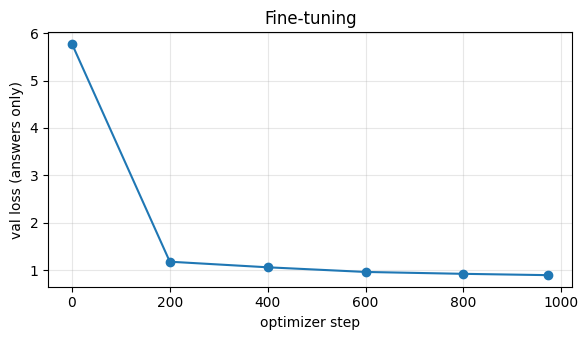

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 3.5)); plt.plot(*zip(*history), "o-")
plt.xlabel("optimizer step"); plt.ylabel("val loss (answers only)"); plt.title("Fine-tuning"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "sft_val_loss.png"), dpi=120); plt.show()

## 4. "After" — what changed
### 4.1 The same questions, now in chat format

In [9]:
model.eval(); torch.manual_seed(0)
after = {q: answer_chat(model, q) for q in QUESTIONS}
for q in QUESTIONS:
    print(f"Q: {q[-90:]}\n  before: {before[q][:160]!r}\n  after : {after[q][:300]!r}\n")

Q: What is the capital of France?
  before: 'Capital is a set of assets or assets that represent ownership of a country or company. It is a set of elements that represent ownership and are used in a way th'
  after : 'The capital of France is Paris.'

Q: What is photosynthesis?
  before: 'In organic chemistry, respiration is the process by which a living organism converts energy into energy to perform a specific function.\nAnswer: In organic chemi'
  after : 'Photosynthesis is the process by which plants and algae convert light energy from the sun into chemical energy stored in glucose. This energy is used to create glucose, a type of sugar that can be used in various crops, such as fruits, vegetables, grains, and even fuel cells.\n\nPhotosynthesis is the '

Q: Who wrote Romeo and Juliet?
  before: 'Romeo and Juliet are two famous romantic novels.\n* In the novel, Romeo and Juliet are lovers.\n* In the novel, Romeo and Juliet are lovers.\n* In the novel, Romeo'
  after : 'The Roman poe

### 4.2 SQuAD: answering from a passage
For held-out SQuAD questions the model answers greedily (always the most likely token). **Exact match** = the answer is identical to the reference after lower-casing and removing punctuation/articles; **F1** gives partial credit for overlapping words. For reference: early neural readers (2016) scored ~40% EM; a 100M model trained from scratch on 1.5B tokens will be well below modern systems — what matters is the change from "can't do it at all" to "often finds the answer".

In [10]:
def norm_answer(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def f1(pred, gold):
    p, g = norm_answer(pred).split(), norm_answer(gold).split()
    common = sum((collections.Counter(p) & collections.Counter(g)).values())
    if common == 0: return 0.0
    prec, rec = common / len(p), common / len(g)
    return 2 * prec * rec / (prec + rec)

squad_val = [x for x in val_set if x["source"] == "squad"][: (20 if SMOKE_TEST else 300)]
em = f1s = 0.0; examples = []
for x in squad_val:
    q, gold = x["messages"][0]["content"], x["messages"][1]["content"]
    pred = answer_chat(model, q, n=32, temperature=0)
    em += norm_answer(pred) == norm_answer(gold); f1s += f1(pred, gold)
    if len(examples) < 5: examples.append((q.split("Question:")[-1].strip(), gold, pred))
squad = {"exact_match": em / max(1, len(squad_val)), "f1": f1s / max(1, len(squad_val)), "n": len(squad_val)}
print(f"SQuAD ({squad['n']} questions): exact match {squad['exact_match']:.1%} | F1 {squad['f1']:.1%}\n")
for q, g, p in examples: print(f"Q: {q}\n   gold: {g!r}\n   model: {p!r}")

SQuAD (300 questions): exact match 32.3% | F1 40.3%

Q: What year in the 1990s did an unusual blizzard visit Tennessee?
   gold: '1993'
   model: '1993'
Q: Who formed the new French Army of Chalons?
   gold: 'Napoleon III and MacMahon'
   model: 'General Auguste Ducrot'
Q: How many members of ethnic minorities are there?
   gold: '400,000'
   model: '200,000'
Q: Another name for errors in programs are called what?
   gold: '"bugs'
   model: 'bugs'
Q: The lower case letters caused a differ in the patter, what did this cause?
   gold: 'simplified case-insensitive character matching and the construction of keyboards and printers'
   model: 'the characters to differ in bit pattern'


### 4.3 HellaSwag after fine-tuning
Fine-tuning teaches *format*, not new knowledge, so HellaSwag usually stays about the same (±1–2 points). A big drop would mean the fine-tune damaged what pretraining learned (then lower the learning rate).

In [11]:
hs_after = hellaswag_acc(model, hs_items)
if hs_after is not None:
    print(f"HellaSwag: base {hs_before:.1%} → fine-tuned {hs_after:.1%}  (random = 25%, GPT-2 124M ≈ 29%)")

## 5. Export for your PC
`tv2_chat_export.zip` contains everything `chat_app.py` needs (~200 MB). The last cell loads the export exactly the way the app does and answers a question — if it prints an answer, the zip works.

**On your PC (GTX 1650):** unzip, open a terminal in the folder, then:
```bash
pip install torch --index-url https://download.pytorch.org/whl/cu121
pip install gradio tokenizers
python chat_app.py          # opens http://127.0.0.1:7860   (or: python chat_app.py --cli)
```

In [12]:
EXPORT = os.path.join(OUT_DIR, "export"); os.makedirs(EXPORT, exist_ok=True)
torch.save({"model": {k: v.half() for k, v in model.state_dict().items()}, "config": pre["config"],
            "special_tokens": SP, "chat_format": manifest["chat_format"], "arch": "transformer_v2",
            "pretrain_tokens": pre.get("tokens", 0)}, os.path.join(EXPORT, "model.pt"))
for f in ("model_v2.py", "chat_app.py"): shutil.copy(f, EXPORT)
shutil.copy(os.path.join(DATA_DIR, "tokenizer.json"), EXPORT)
with open(os.path.join(EXPORT, "README.txt"), "w") as f:
    f.write("My ~100M language model (Transformer v2), trained from scratch.\n\n"
            "Install (NVIDIA GPU):  pip install torch --index-url https://download.pytorch.org/whl/cu121\n"
            "                       pip install gradio tokenizers\n"
            "Run:                   python chat_app.py        (web page at http://127.0.0.1:7860)\n"
            "                       python chat_app.py --cli  (terminal)\n")

results = {"model": "transformer_v2", "params": model.num_params(), "pretrain_tokens": pre.get("tokens", 0),
           "sft": SFT, "sft_val_loss": history, "hellaswag": {"base": hs_before, "sft": hs_after},
           "squad": squad, "answers": {"before": before, "after": after}}
json.dump(results, open(os.path.join(OUT_DIR, "results.json"), "w"), indent=1)
shutil.copy(os.path.join(OUT_DIR, "results.json"), EXPORT)

zip_path = shutil.make_archive(os.path.join(OUT_DIR, "tv2_chat_export"), "zip", EXPORT)
print(f"export: {zip_path} ({os.path.getsize(zip_path)/1e6:.0f} MB)")

# self-check: load the export exactly like the app does
sys.path.insert(0, EXPORT)
import chat_app; importlib.reload(chat_app)
engine = chat_app.Engine(EXPORT, dev)
reply = list(engine.stream(engine.build_prompt([], "What is the capital of France?", 60), max_new=60))[-1]
print("export self-check — Q: What is the capital of France?  A:", reply)

export: /kaggle/working/tv2_sft/tv2_chat_export.zip (233 MB)
Loaded 101M-parameter model on cuda | context 1024 tokens
export self-check — Q: What is the capital of France?  A: The capital of France is Paris.
